In [1]:
# "C:\Users\Rahul Yadav\Downloads\Animal Classification Data\train"

In [2]:
# from torchvision.datasets import ImageFolder
# from torchvision import transforms

# dataset = ImageFolder(root=r"C:\Users\Rahul Yadav\Downloads\Animal Classification Data\train",transform=transforms.ToTensor())


In [3]:
# dataset

In [4]:
# from PIL import Image
# from PIL.ExifTags import TAGS

# img = Image.open(r"C:\Users\Rahul Yadav\Desktop\Animal Detection\8d3e0003d76c5c23.jpg")
# exif_data = img.getexif()

# for tag_id, value in exif_data.items():
#     tag_name = TAGS.get(tag_id, tag_id)
#     print(tag_name, value)

In [5]:
import os
os.chdir(r'C:\Users\Rahul Yadav\Desktop\Animal Detection')

In [6]:
import os
import pandas as pd
import cv2
from src.utils.utils import load_img,load_bbox,crop_it

## EDA

In [7]:
import matplotlib.pyplot as plt

In [8]:
df = pd.read_csv('crop-img.csv')

In [9]:
df['Animal'].values

<ArrowStringArray>
[ 'Bear',  'Bear',  'Bear',  'Bear',  'Bear',  'Bear',  'Bear',  'Bear',
  'Bear',  'Bear',
 ...
 'Zebra', 'Zebra', 'Zebra', 'Zebra', 'Zebra', 'Zebra', 'Zebra', 'Zebra',
 'Zebra', 'Zebra']
Length: 18303, dtype: str

In [10]:
animal_counts = df['Animal'].value_counts()

<Axes: >

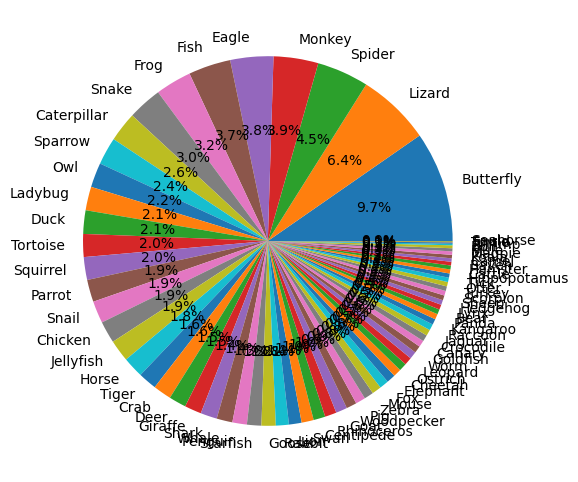

In [11]:
animal_counts.plot(
    kind='pie',
    autopct = '%1.1f%%',
    figsize=(6,6)
)

In [12]:
img = cv2.imread(r'C:\Users\Rahul Yadav\Desktop\Animal Detection\8d3e0003d76c5c23.jpg')

In [13]:
img = img/255

In [14]:
img.max()

np.float64(1.0)

In [15]:
# plt.imshow(flipped)
# plt.show()

In [16]:
flipped = cv2.flip(img,5)

In [17]:
from tqdm.auto import tqdm

## Validation

In [18]:
import hashlib
from collections import defaultdict
from pathlib import Path

In [19]:
hash_dict = defaultdict(list)

In [20]:
for index,row in tqdm(df.iterrows(),):
    img_path = row['Path']
    if img_path.split('.')[-1] not in ['.png','.jpeg','.jpg']:
        continue
    img = cv2.imread(img_path)
    if img is None:
        continue
    img_hash = hashlib.md5(img.tobytes()).hexdigest()
    hash_dict[img_hash].append(str(img_path))

    

0it [00:00, ?it/s]

In [21]:
duplicates = {
    key: paths
    for key, paths in hash_dict.items()
    if len(paths) > 1
}

In [22]:
print("Duplicate groups:", len(duplicates))

Duplicate groups: 0


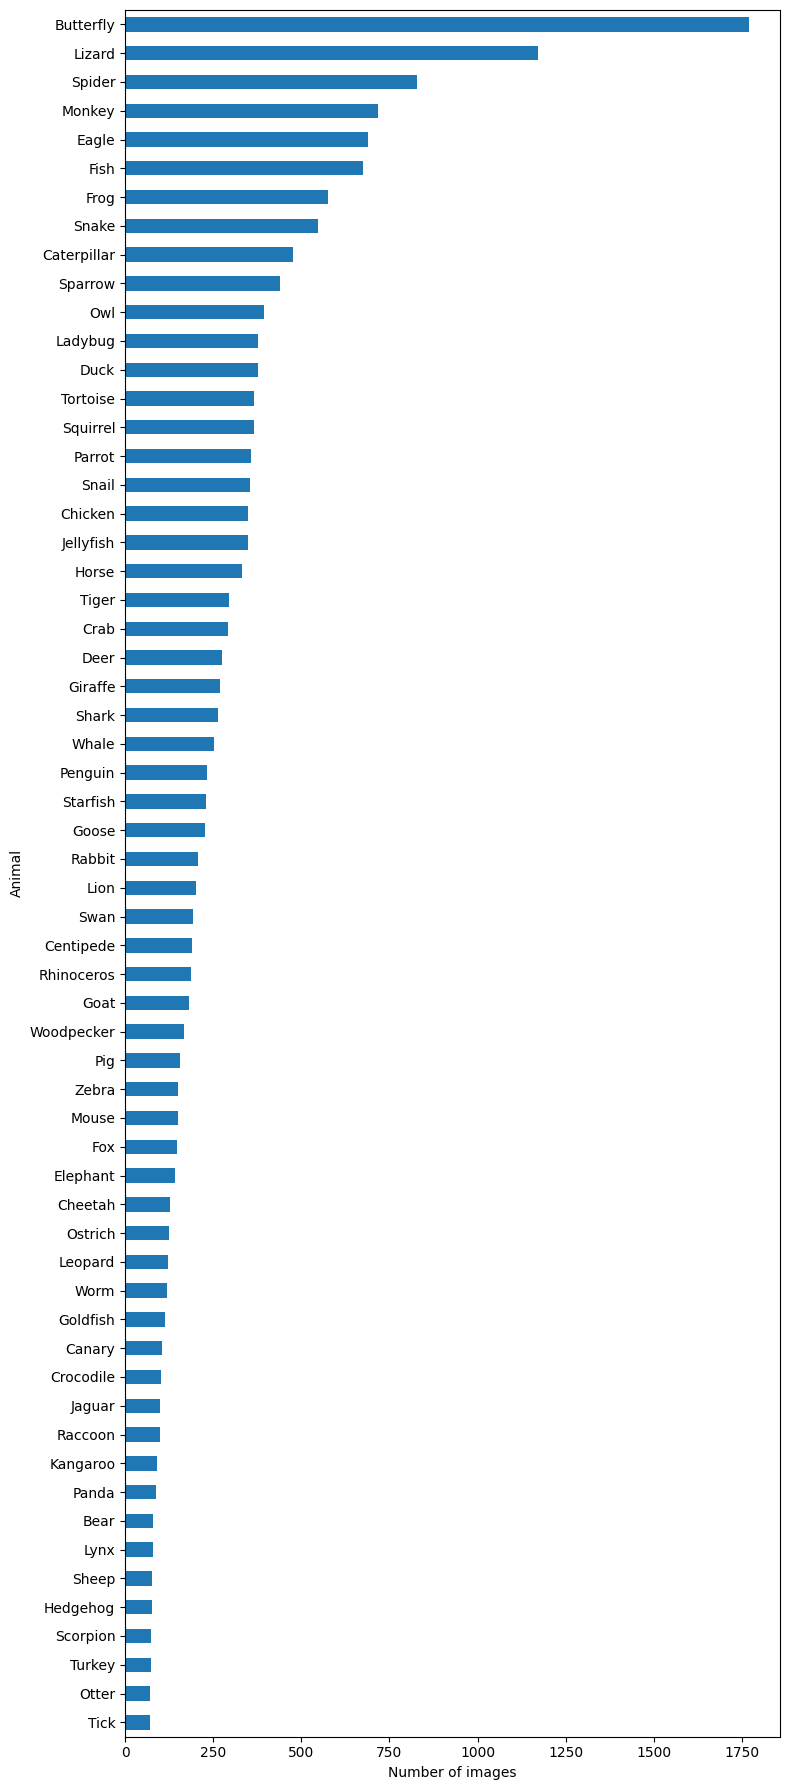

count      60.000000
mean      295.333333
std       288.860277
min        70.000000
25%       117.500000
50%       205.000000
75%       358.250000
max      1769.000000
Name: count, dtype: float64
Imbalance ratio: 25.271428571428572


In [72]:
import matplotlib.pyplot as plt

counts = df['Animal'].value_counts() 
plt.figure(figsize=(8, 18))
counts.sort_values().plot(kind='barh')
plt.xlabel('Number of images')
plt.tight_layout()
plt.show()
print(counts.describe())
print("Imbalance ratio:", counts.max() / counts.min())

In [69]:
count = df['Animal'].value_counts()[lambda x:x<70]

In [70]:
x = count.index.to_list()

In [71]:
x

[]

In [ ]:
df = df[df['Animal']]

Hippopotamus
Cattle
Hamster
Raven
Camel
Koala
Magpie
Mule
Bull
Shrimp
Turtle
Squid
Seahorse


In [68]:
df = df.drop(df[df['Animal'].isin(x)].index)

In [ ]:
max_images = 300

balanced_df = (
    df.groupby(['Animal'],group_keys=False).apply(
        lambda x:x.sample(
            n = min(len(x),max_images),
            random_state = 42
        )
    ).reset_index(drop=True)
)

ValueError: level name Animal is not the name of the index

In [79]:
balanced_df.value_counts()

Path                                                                     
C:\Users\Rahul Yadav\Desktop\cropped_img\train\Bear\1aa1ff24b8e00fc1.jpg     1
C:\Users\Rahul Yadav\Desktop\cropped_img\train\Bear\0155b267ade95d1e.jpg     1
C:\Users\Rahul Yadav\Desktop\cropped_img\train\Bear\112076aeba9d4d0c.jpg     1
C:\Users\Rahul Yadav\Desktop\cropped_img\train\Bear\20500caecb550ddf.jpg     1
C:\Users\Rahul Yadav\Desktop\cropped_img\train\Bear\0cb082f518f55fc3.jpg     1
                                                                            ..
C:\Users\Rahul Yadav\Desktop\cropped_img\train\Zebra\3ddbc3641e0d2877.jpg    1
C:\Users\Rahul Yadav\Desktop\cropped_img\train\Zebra\6e4b1f3adda789a3.jpg    1
C:\Users\Rahul Yadav\Desktop\cropped_img\train\Zebra\0bf2ce2142515aa6.jpg    1
C:\Users\Rahul Yadav\Desktop\cropped_img\train\Zebra\56e6d0536ae4169a.jpg    1
C:\Users\Rahul Yadav\Desktop\cropped_img\train\Zebra\688f367ddf28403d.jpg    1
Name: count, Length: 12207, dtype: int64

In [82]:
max_img = 300
balanced = pd.concat([
    group.sample(n=min(len(group),max_img),random_state = 42)
    for _,group in df.groupby('Animal')
]).reset_index(drop=True)

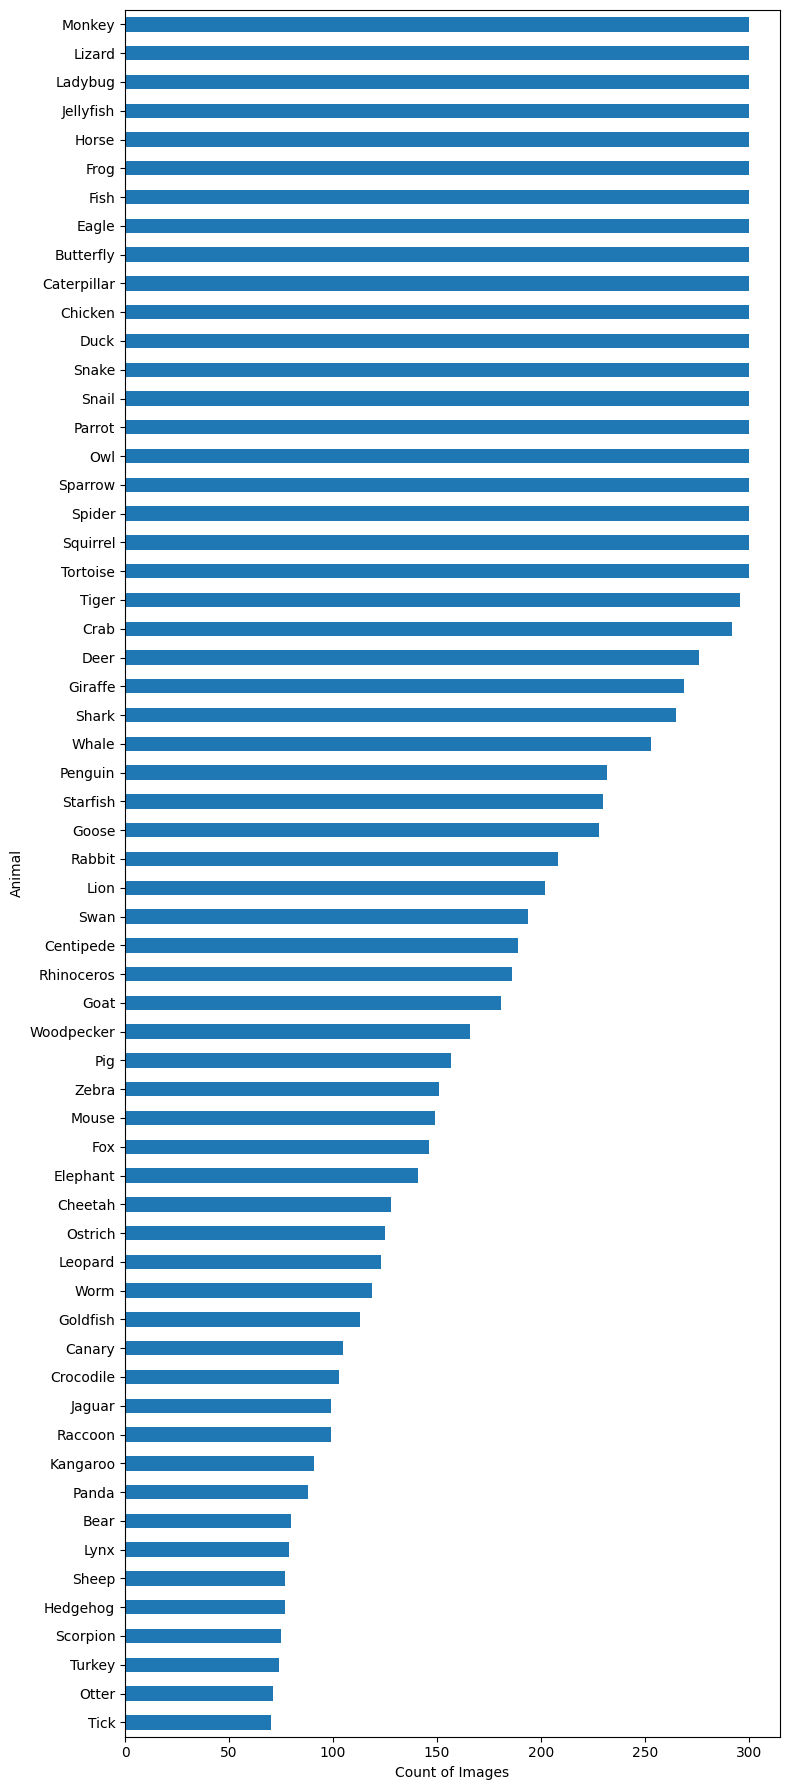

In [85]:
count = balanced['Animal'].value_counts()
plt.figure(figsize=(8,18))
count.sort_values().plot(kind='barh')
plt.xlabel('Count of Images')
plt.tight_layout()
plt.show()